# Análisis Exploratorio para el conjunto de datos desempeño escolar en lengua portuguesa

Ariana Guadalupe Rosales Villalobos | A01644773

### Descripción del conjunto de datos:

* Una fila representa un estudiante de la asignatura de lengua portuguesa en una de dos escuelas secundarias de Portugal. No se mezclan las tablas de matemáticas y portugués.
*  Registros: 360. Cada archivo es una muestra aleatoria simple sin reemplazo de la tabla fuente.
* Los conjuntos de distintos alumnos pueden compartir observaciones.
* Archivo UTF-8. Las líneas que comienzan con # son comentarios; la tabla CSV comienza en la primera línea sin #.
*  Separador: coma. Separador decimal: punto. NA indica dato faltante; cero es un valor observado.
* Se retiraron algunos valores con fines de evaluación. La selección de columnas y el ocultamiento son modificaciones docentes.

* G1 y G2 corresponden a periodos anteriores a G3. Las categorías de horas y educación son ordinales. Las observaciones pertenecen a solo dos escuelas.
* VARIABLES en el orden de la tabla:
-  id_registro: Identificador local de la fila, sin significado estadístico.
-  G3: Calificación final en lengua portuguesa, de 0 a 20 puntos.
-  G1: Calificación del primer periodo en lengua portuguesa, de 0 a 20 puntos.
- G2: Calificación del segundo periodo en lengua portuguesa, de 0 a 20 puntos.
- age: Edad del estudiante, en años.
- absences: Número de ausencias escolares registradas.
- school: Escuela: GP=Gabriel Pereira; MS=Mousinho da Silveira.
-  sex: Sexo registrado: F=femenino; M=masculino.
-  address: Zona de residencia: U=urbana; R=rural.
- Fedu: Educación del padre: 0=ninguna; 1=primaria hasta cuarto grado; 2=quinto a noveno grado; 3=secundaria; 4=superior.
- famsup: Apoyo educativo familiar: yes=sí; no=no.
- internet: Acceso a internet en casa: yes=sí; no=no.
- activities: Participación en actividades extracurriculares: yes=sí; no=no.

*Fuente: https://archive.ics.uci.edu/dataset/320/student+performance
 Atribución: Cortez (2008). Student Performance. UCI. CC BY 4.0. Archivo student-por.csv.*


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

### Cargamos los datos 

In [3]:
df = pd.read_csv(
    "alumno_23_estudiantes.txt",
    na_values=["NA"]
)

df.head()

,id_registro,G3,G1,G2,age,absences,school,sex,address,Fedu,famsup,internet,activities
0,23-001,13,14.0,13.0,16,NaN,MS,F,U,3,no,yes,yes
1,23-002,19,18.0,19.0,17,0.0,GP,F,R,1,yes,no,no
2,23-003,10,10.0,10.0,15,0.0,MS,F,R,1,yes,yes,no
3,23-004,12,11.0,11.0,17,5.0,MS,F,R,1,no,yes,yes
4,23-005,13,13.0,12.0,15,0.0,GP,F,U,3,no,yes,no


## Descripción del conjunto de datos

In [4]:
print("Dimensiones:", df.shape)

print("\nColumnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

print("\nInformación general:")
df.info()



Dimensiones: (360, 13)

Columnas:
['id_registro', 'G3', 'G1', 'G2', 'age', 'absences', 'school', 'sex', 'address', 'Fedu', 'famsup', 'internet', 'activities']

Tipos de datos:
id_registro        str
G3               int64
G1             float64
G2             float64
age              int64
absences       float64
school             str
sex                str
address            str
Fedu             int64
famsup             str
internet           str
activities         str
dtype: object

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id_registro  360 non-null    str    
 1   G3           360 non-null    int64  
 2   G1           331 non-null    float64
 3   G2           324 non-null    float64
 4   age          360 non-null    int64  
 5   absences     317 non-null    float64
 6   school       360 non-null    str    
 7   sex         

Identificamos los tipos de datos contenidos en el conjunto de datos

In [5]:
print("Registros duplicados:", df.duplicated().sum())

print("\nValores faltantes:")
display(
    pd.DataFrame({
        "n_faltantes": df.isna().sum(),
        "porcentaje": df.isna().mean() * 100
    }).sort_values("porcentaje", ascending=False)
)

Registros duplicados: 0

Valores faltantes:


,n_faltantes,porcentaje
absences,43,11.944444
address,36,10.000000
G2,36,10.000000
G1,29,8.055556
id_registro,0,0.000000
age,0,0.000000
G3,0,0.000000
school,0,0.000000
sex,0,0.000000
Fedu,0,0.000000


Encontramos valores faltantes en 'absences' del alumano, direcciones y periodos de tiempo desde G1 - G2

In [6]:
for columna in df.columns:
    print(f"\n--- {columna} ---")
    print(df[columna].value_counts(dropna=False).sort_index())


--- id_registro ---
id_registro
23-001    1
23-002    1
23-003    1
23-004    1
23-005    1
         ..
23-356    1
23-357    1
23-358    1
23-359    1
23-360    1
Name: count, Length: 360, dtype: int64

--- G3 ---
G3
0      5
5      1
6      1
7      4
8     24
9     17
10    56
11    60
12    37
13    47
14    33
15    25
16    21
17    18
18     9
19     2
Name: count, dtype: int64

--- G1 ---
G1
4.0      1
5.0      1
6.0      6
7.0     16
8.0     25
9.0     27
10.0    43
11.0    45
12.0    45
13.0    40
14.0    37
15.0    14
16.0    15
17.0    11
18.0     4
19.0     1
NaN     29
Name: count, dtype: int64

--- G2 ---
G2
0.0      2
5.0      1
6.0      1
7.0     10
8.0     21
9.0     32
10.0    41
11.0    56
12.0    43
13.0    37
14.0    27
15.0    19
16.0    13
17.0    13
18.0     7
19.0     1
NaN     36
Name: count, dtype: int64

--- age ---
age
15     57
16    108
17     88
18     82
19     19
20      5
22      1
Name: count, dtype: int64

--- absences ---
absences
0.0     116
1.0

In [ ]:
df.shape
df.dtypes
df.isna().sum()
df.isna().mean() * 100
df.duplicated().sum()

id_registro  G3  G1    G2    age  absences  school  sex  address  Fedu  famsup  internet  activities
23-002       19  18.0  19.0  17   0.0       GP      F    R        1     yes     no        no            1
23-003       10  10.0  10.0  15   0.0       MS      F    R        1     yes     yes       no            1
23-004       12  11.0  11.0  17   5.0       MS      F    R        1     no      yes       yes           1
23-005       13  13.0  12.0  15   0.0       GP      F    U        3     no      yes       no            1
23-006       13  13.0  14.0  16   5.0       MS      F    R        2     yes     yes       no            1
                                                                                                       ..
23-354       11  12.0  11.0  17   6.0       GP      F    R        4     yes     no        no            1
23-355       14  11.0  11.0  17   0.0       GP      M    U        1     no      yes       yes           1
23-357       17  17.0  18.0  17   2.0       GP     

### Patrones de ausencia 

Buscamos cuantos estudiantes tienen un dato faltante y buscamos relaciones que conicidan entre variables.

In [8]:
columnas_faltantes = ["G1", "G2", "absences", "address"]

# Cantidad de valores faltantes por estudiante
faltantes_por_fila = df.isna().sum(axis=1)

print("Estudiantes con al menos un faltante:",
      (faltantes_por_fila > 0).sum())

print("Estudiantes con datos completos:",
      (faltantes_por_fila == 0).sum())

print("\nCantidad de faltantes por estudiante:")
print(faltantes_por_fila.value_counts().sort_index())

# Patrones de ausencia por variable
patrones = (
    df[columnas_faltantes]
    .isna()
    .astype(int)
    .value_counts()
    .reset_index(name="frecuencia")
    .sort_values("frecuencia", ascending=False)
)

print("\nPatrones de valores faltantes:")
display(patrones)

# Duplicados sin considerar el identificador
print("\nDuplicados exactos:",
      df.duplicated().sum())

print("Filas coincidentes sin identificador:",
      df.drop(columns="id_registro").duplicated().sum())

Estudiantes con al menos un faltante: 119
Estudiantes con datos completos: 241

Cantidad de faltantes por estudiante:
0    241
1     95
2     23
3      1
Name: count, dtype: int64

Patrones de valores faltantes:


,G1,G2,absences,address,frecuencia
0,0,0,0,0,241
1,0,0,1,0,29
2,0,0,0,1,25
3,0,1,0,0,24
4,1,0,0,0,17
5,0,1,1,0,5
6,1,0,1,0,4
7,0,0,1,1,4
8,1,1,0,0,4
9,0,1,0,1,3



Duplicados exactos: 0
Filas coincidentes sin identificador: 0


## Comparamos si los datos faltantes se relacionan con la calificación final de G3

,count,mean,median,std,min,max
tiene_faltantes,,,,,,
False,241,11.929461,12.0,3.179230,0,19
True,119,12.294118,12.0,2.762807,5,18


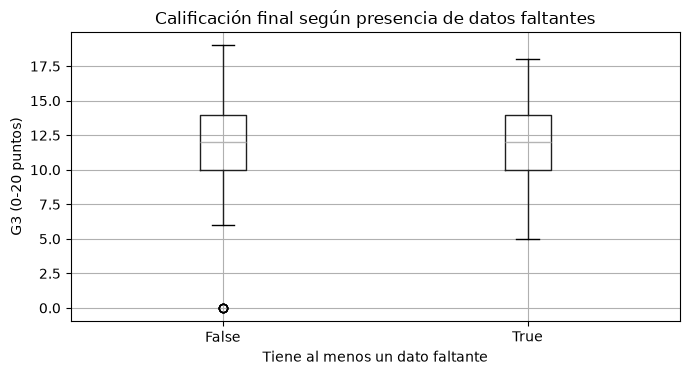

In [9]:
# Indicador de ausencia en al menos una variable
df["tiene_faltantes"] = df[
    ["G1", "G2", "absences", "address"]
].isna().any(axis=1)

# G3 según presencia de faltantes
resumen = df.groupby("tiene_faltantes")["G3"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(resumen)

# Comparación gráfica
fig, ax = plt.subplots(figsize=(7, 4))

df.boxplot(
    column="G3",
    by="tiene_faltantes",
    ax=ax
)

ax.set_title("Calificación final según presencia de datos faltantes")
ax.set_xlabel("Tiene al menos un dato faltante")
ax.set_ylabel("G3 (0-20 puntos)")

plt.suptitle("")
plt.tight_layout()
plt.show()

### Evaluación preliminar de los valores faltantes

Se identificaron 119 estudiantes con al menos un valor faltante y 241 estudiantes con registros completos. Para explorar si la ausencia de información se relacionaba con el desempeño académico, se compararon las distribuciones de la calificación final (G3) entre ambos grupos.

Las medianas fueron iguales (12 puntos), mientras que las medias fueron de 11.93 para los estudiantes con registros completos y 12.29 para aquellos con al menos un dato faltante. La diferencia observada entre medias fue de aproximadamente 0.36 puntos.

El grupo de registros completos presentó una dispersión ligeramente mayor, con una desviación estándar de 3.18 frente a 2.76 puntos.

Estos resultados no muestran una diferencia descriptiva considerable en la tendencia central de G3. No obstante, no permiten concluir que los valores faltantes ocurran completamente al azar. Por ello, se decidió continuar con un análisis individual de las variables que presentan ausencias antes de seleccionar un método de tratamiento.

In [10]:
columnas_faltantes = ["G1", "G2", "absences", "address"]

resultados = []

for variable in columnas_faltantes:

    indicador = df[variable].isna()

    grupo_completo = df.loc[~indicador, "G3"]
    grupo_faltante = df.loc[indicador, "G3"]

    resultados.append({
        "variable": variable,
        "n_observados": len(grupo_completo),
        "n_faltantes": len(grupo_faltante),
        "media_G3_observados": grupo_completo.mean(),
        "media_G3_faltantes": grupo_faltante.mean(),
        "mediana_G3_observados": grupo_completo.median(),
        "mediana_G3_faltantes": grupo_faltante.median(),
        "diferencia_medias": (
            grupo_faltante.mean() - grupo_completo.mean()
        )
    })

tabla_ausencia = pd.DataFrame(resultados)

display(tabla_ausencia.round(3))

,variable,n_observados,n_faltantes,media_G3_observados,media_G3_faltantes,mediana_G3_observados,mediana_G3_faltantes,diferencia_medias
0,G1,331,29,12.021,12.379,12.0,12.0,0.358
1,G2,324,36,11.988,12.611,12.0,12.0,0.623
2,absences,317,43,12.035,12.163,12.0,12.0,0.128
3,address,324,36,12.015,12.361,12.0,12.0,0.346


### Observamos la distribucuonde los faltantes entre ambas escuelas

In [11]:
columnas_faltantes = ["G1", "G2", "absences", "address"]

for variable in columnas_faltantes:

    tabla = pd.crosstab(
        df["school"],
        df[variable].isna(),
        normalize="index"
    ) * 100

    tabla = tabla.rename(
        columns={
            False: "Observado (%)",
            True: "Faltante (%)"
        }
    )

    print(f"\nAusencia de {variable} por escuela")
    display(tabla.round(2))


Ausencia de G1 por escuela


G1,Observado (%),Faltante (%)
school,,
GP,90.87,9.13
MS,94.12,5.88



Ausencia de G2 por escuela


G2,Observado (%),Faltante (%)
school,,
GP,90.46,9.54
MS,89.08,10.92



Ausencia de absences por escuela


absences,Observado (%),Faltante (%)
school,,
GP,87.55,12.45
MS,89.08,10.92



Ausencia de address por escuela


address,Observado (%),Faltante (%)
school,,
GP,90.87,9.13
MS,88.24,11.76


 Se compararon los porcentajes de ausencia entre las escuelas GP y MS. Las diferencias oscilaron entre 1.38 y 3.25 puntos porcentuales en valor absoluto, sin observarse una mayor proporción de faltantes de forma consistente en una misma escuela.

Estos resultados no muestran diferencias descriptivas pronunciadas en las variables examinadas. Sin embargo, no son suficientes para establecer que los datos faltan completamente al azar, ni nos permiten descartar asociaciones con otras características de los estudiantes.

Se decidió conservar los valores faltantes en el conjunto original y realizar los análisis descriptivos con la información disponible para cada variable. Para las etapas de inferencia y regresión, se evaluará el efecto de utilizar casos completos frente a estrategias de imputación, evitando seleccionar un método antes de conocer sus implicaciones sobre los resultados.

## Análisis Univariado

### Estadísticos de las primeras 5 variables

Se hará en análisis descriptivo de las variables numericas del dataset.

Incluimos: 
* G2, G2, G3
* AGE
* Absence


In [12]:
variables_numericas = [
    "G1", "G2", "G3", "age", "absences"
]

resumen = df[variables_numericas].describe().T

resumen["varianza"] = (
    df[variables_numericas].var()
)

resumen["IQR"] = (
    df[variables_numericas].quantile(0.75)
    - df[variables_numericas].quantile(0.25)
)

resumen["asimetria"] = (
    df[variables_numericas].skew()
)

resumen["exceso_curtosis"] = (
    df[variables_numericas].kurt()
)

display(resumen.round(3))

,count,mean,std,min,25%,50%,75%,max,varianza,IQR,asimetria,exceso_curtosis
G1,331.0,11.574,2.780,4.0,10.0,12.0,13.0,19.0,7.730,3.0,0.095,-0.341
G2,324.0,11.719,2.832,0.0,10.0,11.0,13.0,19.0,8.023,3.0,-0.081,1.046
G3,360.0,12.050,3.049,0.0,10.0,12.0,14.0,19.0,9.296,4.0,-0.543,2.059
age,360.0,16.772,1.232,15.0,16.0,17.0,18.0,22.0,1.519,2.0,0.459,0.099
absences,317.0,3.839,4.947,0.0,0.0,2.0,6.0,30.0,24.471,6.0,1.962,4.776


Observamos G3 tiende a tener una asimetría negativa y exceso de curtosis con una desviación estándar (3.049) y el mayor IQR (4 puntos) entre todos los periodos sugiriendo una mayor variabilidad en las calificaciones. 


Absences por otro lado contiene una asimetria positiva lo que implica mayor número de ausencias en ciertos estudiantes y la varianza con 24.471 supera por mucho la media (3.839) implicando una distribución Poisson.

### Generamos histogramas 

Utilizamos intervalos de amplitud 1 porque todas estas variables son conteos o valores enteros registrados en unidades discretas.

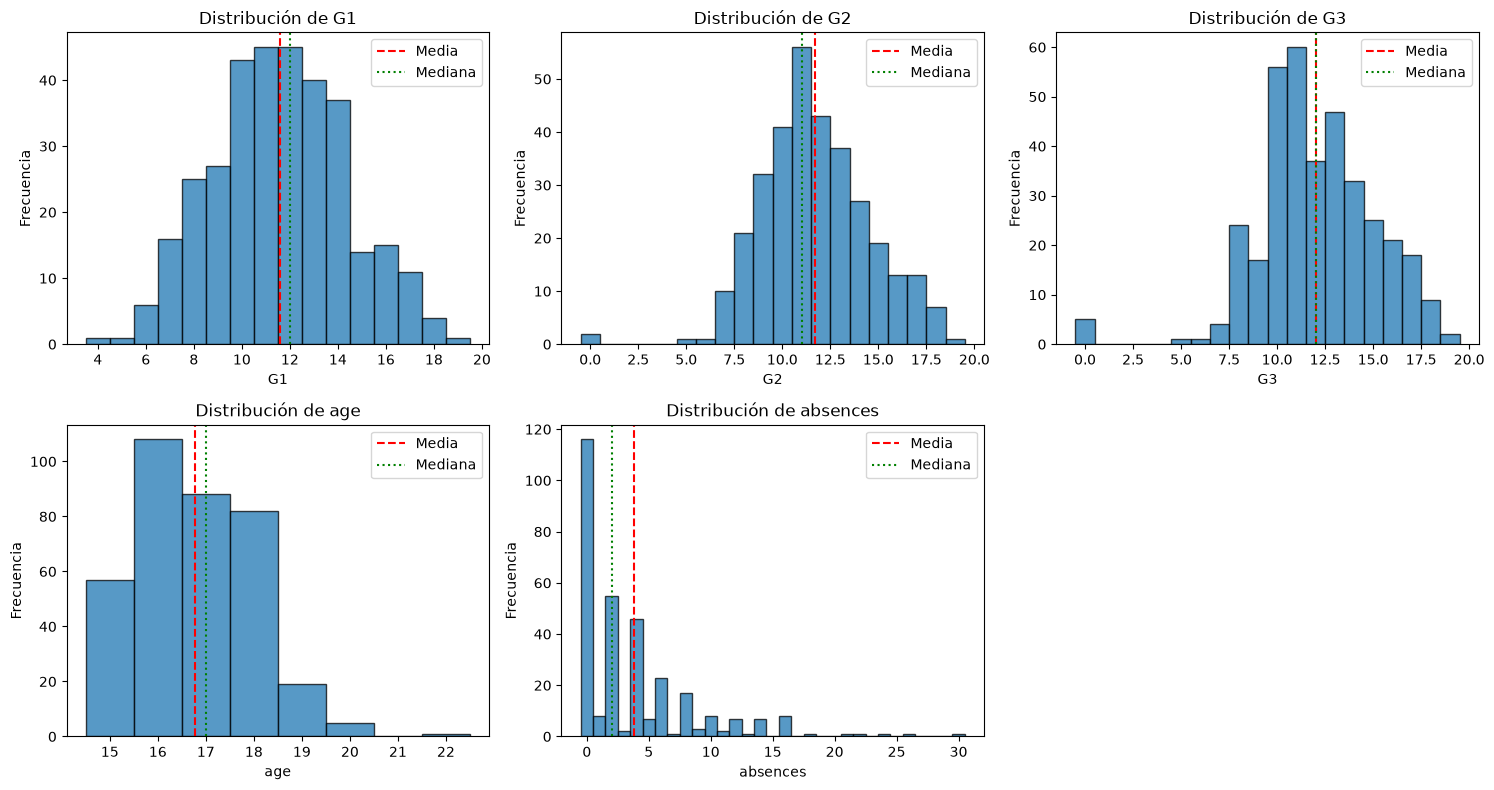

In [ ]:
variables = ["G1", "G2", "G3", "age", "absences"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, variable in enumerate(variables):
    datos = df[variable].dropna()
    valores_min = int(datos.min())
    valores_max = int(datos.max())
    bins = np.arange(
        valores_min - 0.5,
        valores_max + 1.5,
        1
    )

    axes[i].hist(
        datos,
        bins=bins,
        edgecolor="black",
        alpha=0.75
    )

    axes[i].axvline(
        datos.mean(),
        color="red",
        linestyle="--",
        label="Media"
    )

    axes[i].axvline(
        datos.median(),
        color="green",
        linestyle=":",
        label="Mediana"
    )

    axes[i].set_title(f"Distribución de {variable}")
    axes[i].set_xlabel(variable)
    axes[i].set_ylabel("Frecuencia")
    axes[i].legend()

axes[-1].axis("off")

plt.tight_layout()
plt.show()

Observamos que G1 y G2 tienen distribuciones simétricas, sin embargo G2 presenta dos calificaciones iguales a 0 que se encuentran separas de la concentración de las observaciones. 

### Boxplots

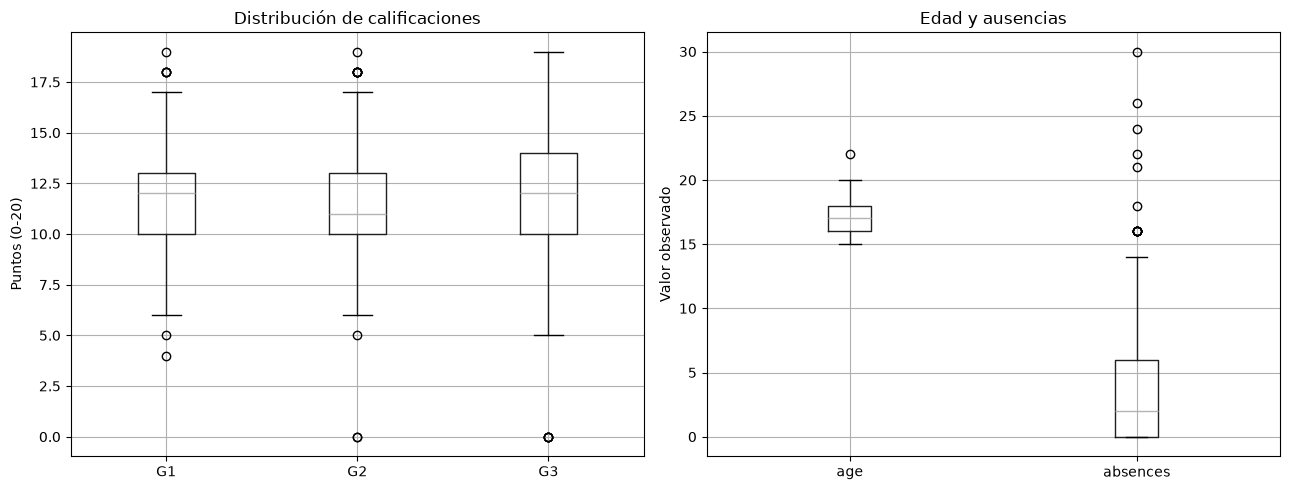

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Calificaciones
df[["G1", "G2", "G3"]].boxplot(ax=axes[0])

axes[0].set_title("Distribución de calificaciones")
axes[0].set_ylabel("Puntos (0-20)")

# Edad y ausencias 
df[["age", "absences"]].boxplot(ax=axes[1])

axes[1].set_title("Edad y ausencias")
axes[1].set_ylabel("Valor observado")

plt.tight_layout()
plt.show()

### Indetificación de valores atípicos

Utilizamos Z.score
Regla de IQR

In [16]:
resultados_atipicos = []

for variable in variables:

    datos = df[variable].dropna()

    Q1 = datos.quantile(0.25)
    Q3 = datos.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    atipicos_iqr = (
        (datos < limite_inferior) |
        (datos > limite_superior)
    )

    z = np.abs(
        (datos - datos.mean()) / datos.std()
    )

    atipicos_z = z > 3

    resultados_atipicos.append({
        "variable": variable,
        "limite_inferior_IQR": limite_inferior,
        "limite_superior_IQR": limite_superior,
        "n_atipicos_IQR": atipicos_iqr.sum(),
        "n_atipicos_z": atipicos_z.sum(),
        "valores_IQR": sorted(datos[atipicos_iqr].unique())
    })

tabla_atipicos = pd.DataFrame(resultados_atipicos)

display(tabla_atipicos)

,variable,limite_inferior_IQR,limite_superior_IQR,n_atipicos_IQR,n_atipicos_z,valores_IQR
0,G1,5.5,17.5,7,0,"[4.0, 5.0, 18.0, 19.0]"
1,G2,5.5,17.5,11,2,"[0.0, 5.0, 18.0, 19.0]"
2,G3,4.0,20.0,5,5,[0]
3,age,13.0,21.0,1,1,[22]
4,absences,-9.0,15.0,14,5,"[16.0, 18.0, 21.0, 22.0, 24.0, 26.0, 30.0]"


Las calificaciones G1 y G2 presentan distribuciones relativamente simétricas, con coeficientes de asimetría de 0.095 y −0.081, respectivamente. Por otra parte, G3 presenta una asimetría negativa de −0.543 y cinco calificaciones iguales a cero, identificadas como atípicas por los métodos IQR y z-score.


La variable 'absences' presenta una distribución  asimétrica hacia la derecha, con una media de 3.84 y una mediana de 2 ausencias. Se identificaron 14 observaciones atípicas mediante IQR y cinco mediante z-score, lo que evidencia que los criterios pueden producir resultados diferentes ante distribuciones asimétricas.

Se decidió conservar todas las observaciones, debido a que los valores identificados se encuentran dentro de los rangos permitidos o no existe evidencia suficiente para considerarlos errores. También se descartó aplicar transformaciones o sustituir valores extremos de manera automática, ya que estas decisiones podrían modificar las características originales de las distribuciones.

Por lo que las mantendermos para observacion y revisaremos si influyen de manera desproporcionada en el resto del análisis, mediante el diagnósticos de residuos, apalancamiento e influencia.

## Análisis descriptivo de variables categóricas

### Tabla de frecuencias 

No calcularemos porcentajes acumulados en las variables nominales, porque sus categorías no tienen un orden estadístico natural. Se usará la tabla de frecuencias absolutas para identificar  la proporción de información ausente de 'address'

In [17]:
variables_categoricas = [
    "school", "sex", "address",
    "Fedu", "famsup", "internet", "activities"
]

for variable in variables_categoricas:

    frecuencias = df[variable].value_counts(
        dropna=False,
        sort=False
    )

    # Ordenar los niveles de Fedu
    if variable == "Fedu":
        frecuencias = frecuencias.sort_index()

    tabla = pd.DataFrame({
        "Frecuencia": frecuencias,
        "Porcentaje (%)": frecuencias / len(df) * 100
    })

    if variable == "Fedu":
        tabla["Porcentaje acumulado (%)"] = (
            tabla["Porcentaje (%)"].cumsum()
        )

    print(f"\nDistribución de {variable}")
    display(tabla.round(2))


Distribución de school


,Frecuencia,Porcentaje (%)
school,,
MS,119,33.06
GP,241,66.94



Distribución de sex


,Frecuencia,Porcentaje (%)
sex,,
F,220,61.11
M,140,38.89



Distribución de address


,Frecuencia,Porcentaje (%)
address,,
U,229,63.61
R,95,26.39
NaN,36,10.00


... (4 outputs left out)


Distribución de internet


,Frecuencia,Porcentaje (%)
internet,,
yes,270,75.0
no,90,25.0



Distribución de activities


,Frecuencia,Porcentaje (%)
activities,,
yes,166,46.11
no,194,53.89


### Gráfica de barras

Esta visualización permitirá comprobar si existen categorías con frecuencias muy bajas

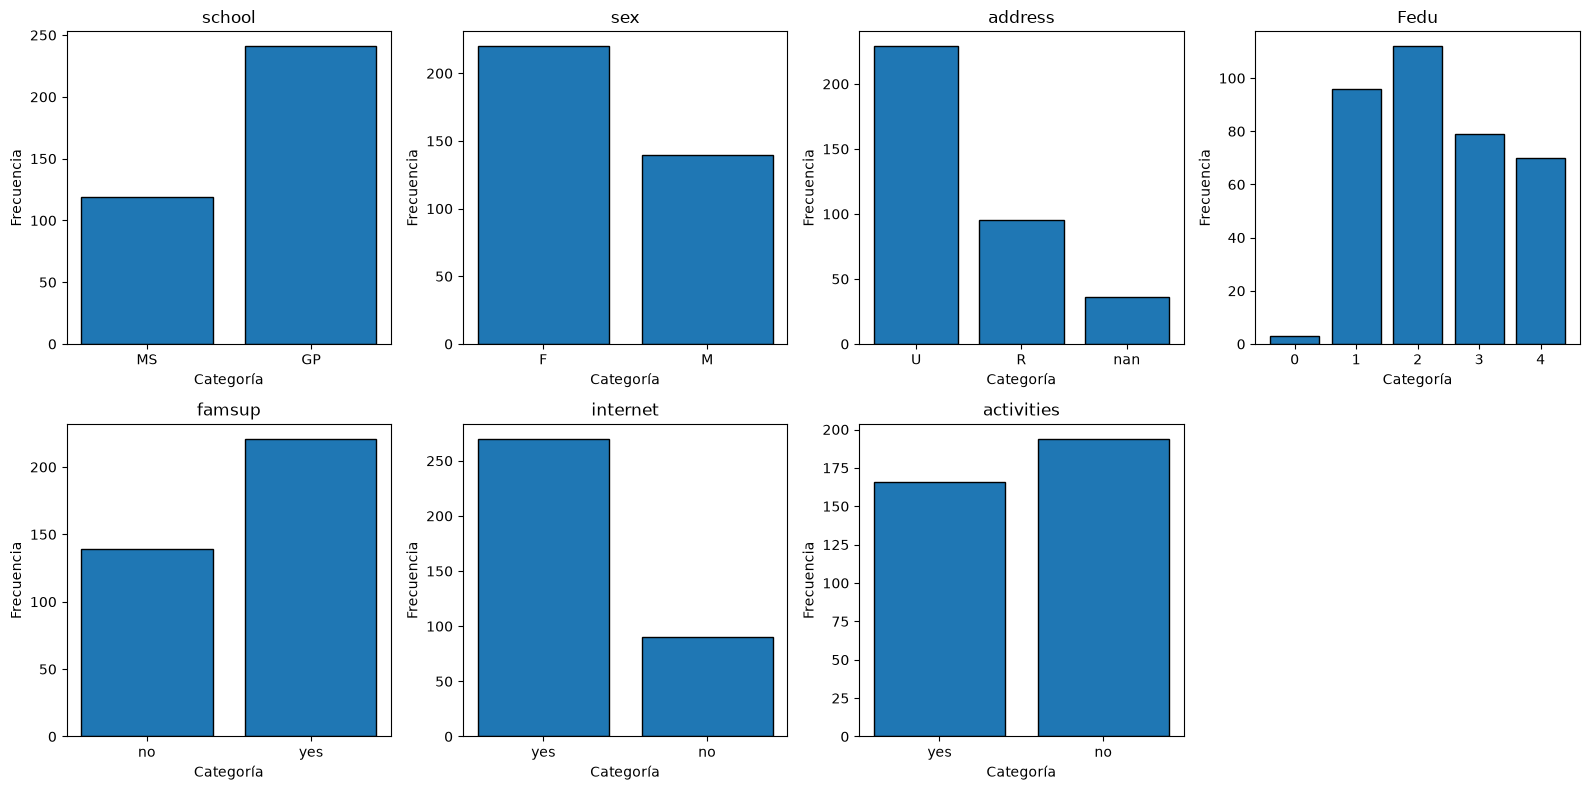

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, variable in enumerate(variables_categoricas):
    frecuencias = df[variable].value_counts(
        dropna=False,
        sort=False
    )

    if variable == "Fedu":
        frecuencias = frecuencias.sort_index()

    frecuencias.index = frecuencias.index.map(str)

    axes[i].bar(
        frecuencias.index,
        frecuencias.values,
        edgecolor="black"
    )

    axes[i].set_title(variable)
    axes[i].set_xlabel("Categoría")
    axes[i].set_ylabel("Frecuencia")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

## Análisis Bivariado

El objetivo de esta sección es explorar qué variables numéricas presentan una asociación descriptiva con la calificación final G3.

Se analizarán G1, G2, age y absences. Para cada relación se reportará el número de observaciones disponibles por pareja, ya que G1, G2 y absences contienen valores faltantes.

### Calculo de correlacion Pearson y Spearman.

 Pearson permite resumir la intensidad de una relación lineal, mientras que Spearman evalúa asociaciones a partir de los rangos y resulta útil como contraste cuando existen distribuciones asimétricas o valores extremos.

En esta etapa las correlaciones se interpretarán de forma descriptiva. 



In [19]:
variables_numericas_g3 = ["G1", "G2", "age", "absences"]

resultados_correlacion = []

for variable in variables_numericas_g3:
    
    datos_pareja = df[[variable, "G3"]].dropna()
    
    n = len(datos_pareja)
    
    pearson = datos_pareja[variable].corr(
        datos_pareja["G3"],
        method="pearson"
    )
    
    spearman = datos_pareja[variable].corr(
        datos_pareja["G3"],
        method="spearman"
    )
    
    resultados_correlacion.append({
        "Variable": variable,
        "n": n,
        "Pearson": pearson,
        "Spearman": spearman
    })

tabla_correlaciones = pd.DataFrame(resultados_correlacion)

display(tabla_correlaciones.round(3))

,Variable,n,Pearson,Spearman
0,G1,331,0.848,0.891
1,G2,324,0.931,0.945
2,age,360,-0.043,-0.015
3,absences,317,-0.134,-0.192


Particularmente, absences presenta la mayor diferencia entre ambos coeficientes, como tambien observamos en el análisis univariado identificamos que esta variable tiene una asimetría positiva de 1.962 y valores extremos.

Es posible que la distribución de las ausencias, la presencia de valores extremos o una relación no estrictamente lineal expliquen parte de esta diferencia. Sin embargo, todavía no tenemos evidencia suficiente para determinar cuál de estas explicaciones es la correcta.

### Visualizar relaciones númericas

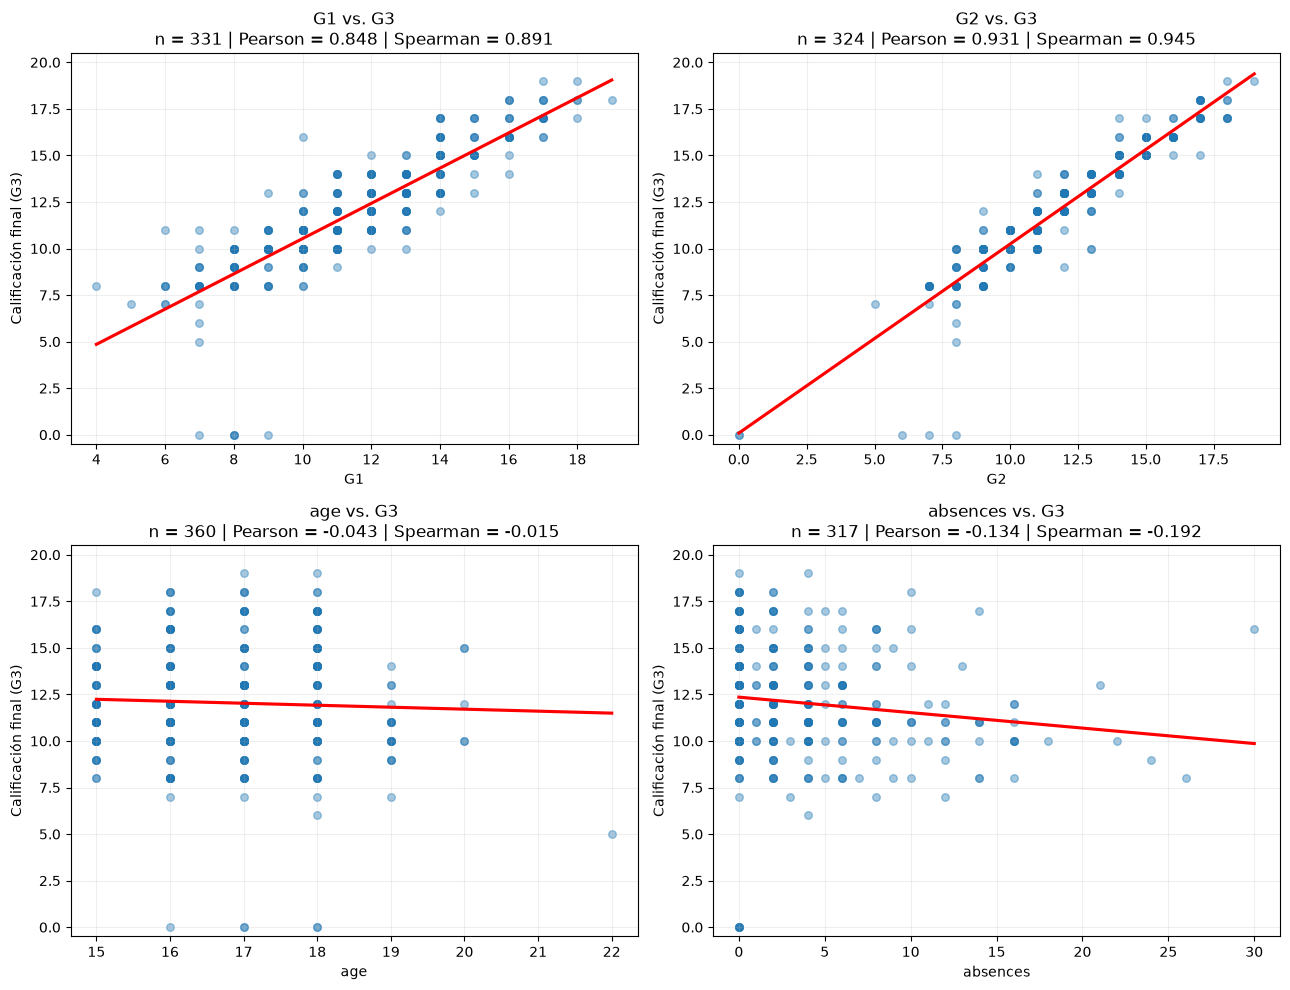

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

variables = ["G1", "G2", "age", "absences"]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for variable, ax in zip(variables, axes.flatten()):
    datos = df[[variable, "G3"]].dropna()
    pearson = datos[variable].corr(
        datos["G3"], method="pearson"
    )

    spearman = datos[variable].corr(
        datos["G3"], method="spearman"
    )

    sns.regplot(
        data=datos,
        x=variable,
        y="G3",
        ax=ax,
        ci=None,
        scatter_kws={"alpha": 0.4, "s": 30},
        line_kws={"color": "red"}
    )

    ax.set_title(
        f"{variable} vs. G3\n"
        f"n = {len(datos)} | "
        f"Pearson = {pearson:.3f} | "
        f"Spearman = {spearman:.3f}"
    )

    ax.set_xlabel(variable)
    ax.set_ylabel("Calificación final (G3)")
    ax.set_ylim(-0.5, 20.5)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

El análisis bivariado de las variables numéricas permitió identificar que las calificaciones de los periodos anteriores, especialmente G2, presentan las mayores asociaciones descriptivas con la calificación final. Por otro lado, las ausencias muestran una asociación negativa débil, mientras que la edad presenta coeficientes de correlación cercanos a cero.

Los diagramas de dispersión respaldan estos resultados y permiten identificar observaciones que se alejan de las tendencias generales, particularmente estudiantes con calificación final igual a cero. Se decidió conservar estas observaciones debido a que representan valores válidos dentro del conjunto de datos.

Estos resultados constituyen una primera aproximación al comportamiento de las variables y no permiten establecer relaciones causales ni conclusiones sobre significancia estadística. Su utilidad principal será orientar los análisis inferenciales y modelos de regresión.

## Análisis bivariado categórico–numérico

Aquí utilizaremos inicialmente estadísticas descriptivas condicionadas por categoría para observar como distribuye la calificación final G3 entre estudiantes con diferentes características sociodemográficas, familiares y escolares.

Al conocer la magnitud de las diferencias, los tamaños de los grupos y sus distribuciones. Posteriormente evaluaremos qué pruebas inferenciales son apropiadas, considerando sus supuestos y las hipótesis de investigación.

### Estadísticas descriptivas por categoría

In [21]:
variables_categoricas = [
    "school",
    "sex",
    "address",
    "famsup",
    "internet",
    "activities",
    "Fedu"
]

for variable in variables_categoricas:
    datos = df[[variable, "G3"]].dropna()

    resumen = datos.groupby(
        variable, observed=True
    )["G3"].agg(
        n="count",
        media="mean",
        mediana="median",
        desviacion="std",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )

    resumen["IQR"] = resumen["Q3"] - resumen["Q1"]

    resumen["porcentaje"] = (
        resumen["n"] / len(datos) * 100
    )

    print(f"\nVariable: {variable}")
    print(f"Observaciones disponibles: {len(datos)}")

    display(resumen.round(3))


Variable: school
Observaciones disponibles: 360


,n,media,mediana,desviacion,Q1,Q3,IQR,porcentaje
school,,,,,,,,
GP,241,12.589,12.0,2.537,11.0,14.0,3.0,66.944
MS,119,10.958,10.0,3.660,9.0,13.5,4.5,33.056



Variable: sex
Observaciones disponibles: 360


,n,media,mediana,desviacion,Q1,Q3,IQR,porcentaje
sex,,,,,,,,
F,220,12.264,12.0,3.066,10.0,14.0,4.0,61.111
M,140,11.714,11.0,3.002,10.0,14.0,4.0,38.889



Variable: address
Observaciones disponibles: 324


,n,media,mediana,desviacion,Q1,Q3,IQR,porcentaje
address,,,,,,,,
R,95,11.526,11.0,3.512,10.0,14.0,4.0,29.321
U,229,12.218,12.0,2.820,11.0,14.0,3.0,70.679


... (4 outputs left out)


Variable: activities
Observaciones disponibles: 360


,n,media,mediana,desviacion,Q1,Q3,IQR,porcentaje
activities,,,,,,,,
no,194,11.985,11.0,2.855,10.0,14.0,4.0,53.889
yes,166,12.127,12.0,3.268,10.0,14.0,4.0,46.111



Variable: Fedu
Observaciones disponibles: 360


,n,media,mediana,desviacion,Q1,Q3,IQR,porcentaje
Fedu,,,,,,,,
0,3,12.667,10.0,4.619,10.00,14.0,4.00,0.833
1,96,11.188,11.0,2.989,9.75,13.0,3.25,26.667
2,112,11.705,11.0,3.468,10.00,14.0,4.00,31.111
3,79,12.506,12.0,2.230,11.00,14.0,3.00,21.944
4,70,13.243,13.0,2.748,11.25,16.0,4.75,19.444


### Diferencia de medias en variables con 2 categorias

In [22]:
variables_binarias = [
    "school",
    "sex",
    "address",
    "famsup",
    "internet",
    "activities"
]

resultados = []
for variable in variables_binarias:
    datos = df[[variable, "G3"]].dropna()

    medias = datos.groupby(
        variable, observed=True
    )["G3"].mean()

    resultados.append({
        "Variable": variable,
        "Grupo 1": medias.index[0],
        "Media 1": medias.iloc[0],
        "Grupo 2": medias.index[1],
        "Media 2": medias.iloc[1],
        "Diferencia (1 - 2)": (
            medias.iloc[0] - medias.iloc[1]
        ),
        "n": len(datos)
    })

tabla_diferencias = pd.DataFrame(resultados)

display(tabla_diferencias.round(3))

,Variable,Grupo 1,Media 1,Grupo 2,Media 2,Diferencia (1 - 2),n
0,school,GP,12.589,MS,10.958,1.631,360
1,sex,F,12.264,M,11.714,0.549,360
2,address,R,11.526,U,12.218,-0.692,324
3,famsup,no,12.043,yes,12.054,-0.011,360
4,internet,no,11.356,yes,12.281,-0.926,360
5,activities,no,11.985,yes,12.127,-0.142,360


Encontramos qe schol es uan variable con mayor diferencia de medias observada, MS presenta una mayor desviación estándar y un mayor rango intercuartílico.

En la bvariable 'sex' se observa una diferencia de medias de 0.549 puntos a favor del grupo femenino, sin embargo, ambos grupos presentan desviaciones estándar similares

La variable 'address' los estudiantes de zonas urbanas presentan una media superior en 0.692 puntos respecto a los estudiantes de zonas rurales. Los estudiantes de zonas rurales presentan una mayor dispersión.

Con la variable 'famsup' aunque ambos grupos presentan prácticamente la misma media, mediana y rango intercuartílico, existe una diferencia en sus desviaciones estándar.
 
En internet Los estudiantes con acceso a internet presentan una media de 12.281, frente a 11.356 de quienes no tienen acceso.

Como ultimo en la variable'activities' la diferencia de medias es de apenas 0.142 puntos a favor de los estudiantes que realizan actividades extracurriculares.
Esto demuestra por qué no debemos limitar nuestro análisis a la comparación de medias. Dos grupos pueden presentar tendencias centrales similares, pero comportamientos diferentes en su dispersión.

##3 Comparamos simultáneamente la mediana, la dispersión, la posición de los cuartiles y la presencia de observaciones extremas entre categorías.

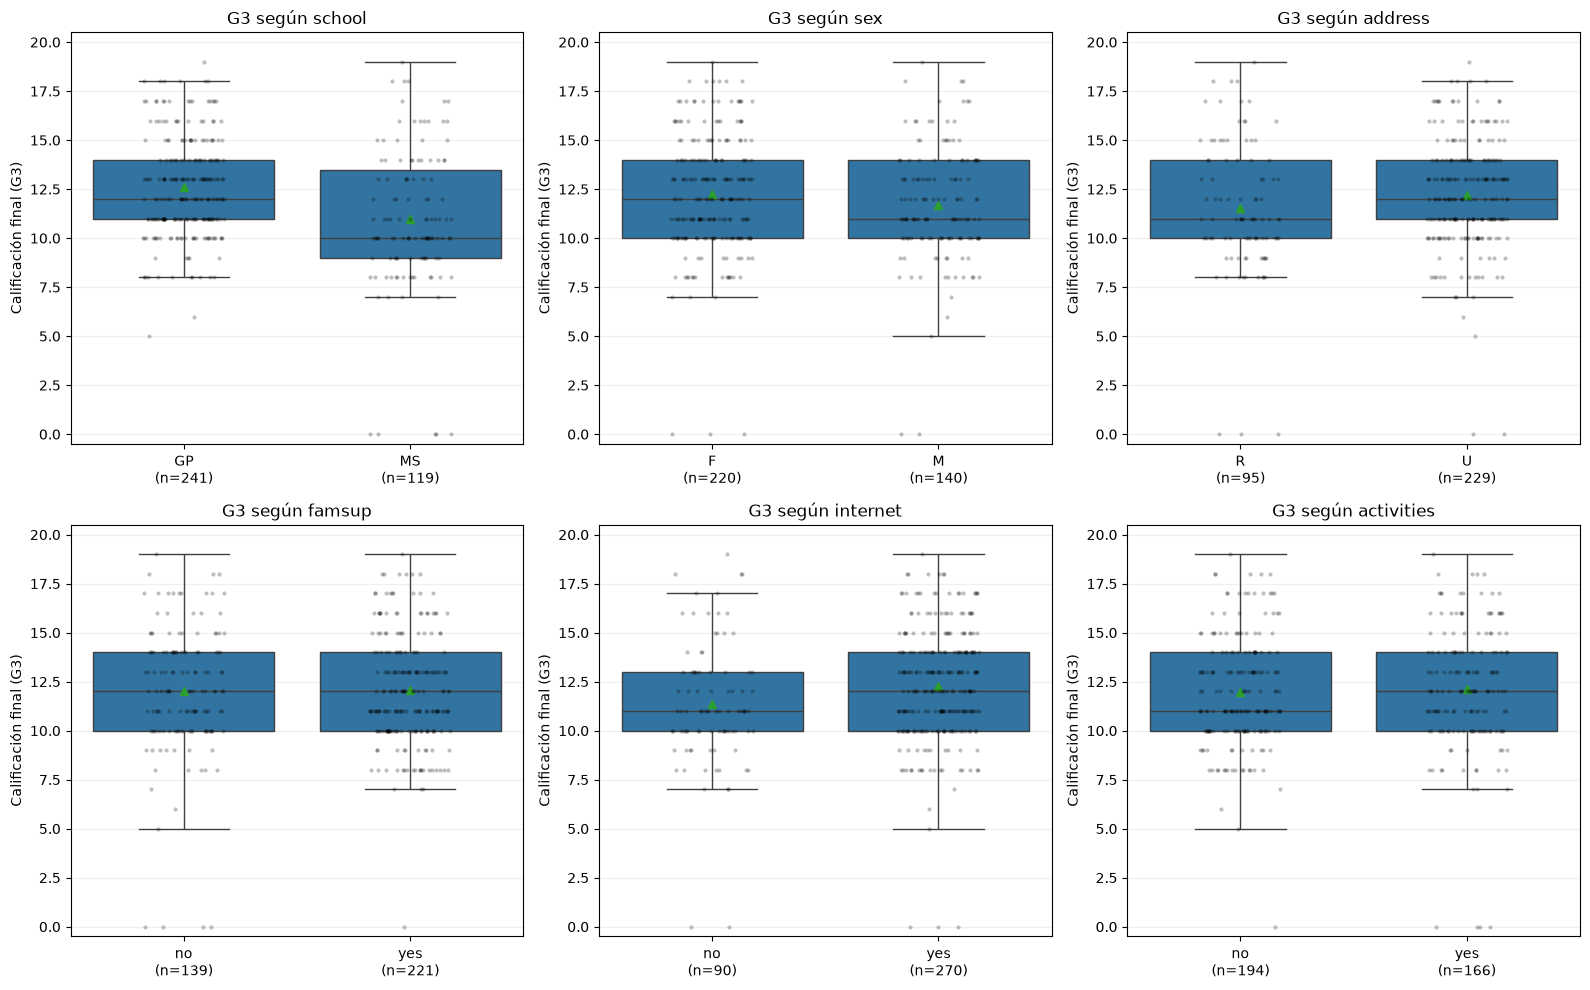

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for variable, ax in zip(
    variables_binarias, axes.flatten()
):

    datos = df[[variable, "G3"]].dropna()
    orden = sorted(datos[variable].unique())

    sns.boxplot(
        data=datos,
        x=variable,
        y="G3",
        order=orden,
        ax=ax,
        showmeans=True,
        showfliers=False
    )

    sns.stripplot(
        data=datos,
        x=variable,
        y="G3",
        order=orden,
        ax=ax,
        color="black",
        alpha=0.25,
        jitter=0.18,
        size=3
    )

    conteos = datos[variable].value_counts()

    ax.set_xticks(
        range(len(orden)),
        labels=[
            f"{grupo}\n(n={conteos[grupo]})"
            for grupo in orden
        ]
    )

    ax.set_title(f"G3 según {variable}")
    ax.set_xlabel("")
    ax.set_ylabel("Calificación final (G3)")
    ax.set_ylim(-0.5, 20.5)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

### Análisis de Fedu

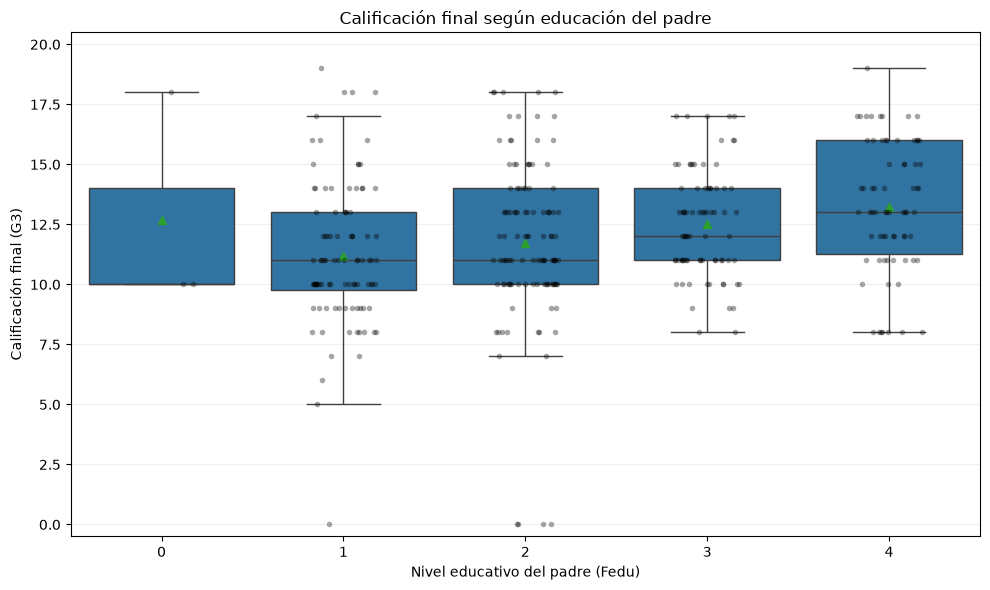

In [27]:
datos_fedu = df[["Fedu", "G3"]].dropna()
orden_fedu = sorted(datos_fedu["Fedu"].unique())


plt.figure(figsize=(10, 6))

sns.boxplot(
    data=datos_fedu,
    x="Fedu",
    y="G3",
    order=orden_fedu,
    showmeans=True,
    showfliers=False
)

sns.stripplot(
    data=datos_fedu,
    x="Fedu",
    y="G3",
    order=orden_fedu,
    color="black",
    alpha=0.35,
    jitter=0.18,
    size=4
)


plt.title("Calificación final según educación del padre")
plt.xlabel("Nivel educativo del padre (Fedu)")
plt.ylabel("Calificación final (G3)")
plt.ylim(-0.5, 20.5)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

En términos descriptivos, la escuela, el nivel educativo del padre, el acceso a internet y la ubicación de la vivienda presentan patrones de asociación con la calificación final que resulta pertinente estudiar posteriormente mediante métodos inferenciales y multivariados.

Sin embargo, estas comparaciones se realizaron de manera individual, sin controlar la posible asociación entre las características de los estudiantes. Por ejemplo, la distribución del nivel educativo del padre o del acceso a internet podría diferir entre escuelas.

Por esta razón, el siguiente análisis explorará las relaciones entre las propias variables categóricas mediante tablas de contingencia, con el objetivo de contextualizar las diferencias observadas en G3


### Correlación de Spearman para Fedu 

In [29]:
datos_fedu = df[["Fedu", "G3"]].dropna().copy()

datos_fedu["Fedu"] = datos_fedu["Fedu"].astype(int)

rho_fedu = datos_fedu["Fedu"].corr(
    datos_fedu["G3"],
    method="spearman"
)

print(f"Observaciones disponibles: {len(datos_fedu)}")
print(f"Spearman Fedu-G3: {rho_fedu:.3f}")

Observaciones disponibles: 360
Spearman Fedu-G3: 0.267


Encontramos una sociación monotónica positiva débil entre el nivel educativo del padre y la calificación final.. Este resultado es consistente con los resultados en los boxplots ja, donde las medias aumentaban progresivamente entre los niveles 1 y 4. Sin embargo, la magnitud del coeficiente indica que el nivel educativo del padre, considerado individualmente, tiene una capacidad limitada para explicar las diferencias en el rendimiento académico..

#### Generamos tablas de frecuencias absolutas, porcentajes por fila yPorcentajes por columna

Para análisis posteriores la prueba de independencia chi-cuadrado será una alternativa para la etapa inferencial. Sin embargo, antes debemos revisar las frecuencias observadas y posteriormente comprobar las frecuencias esperadas.

En particular, las tablas que incluyen Fedu podrían presentar frecuencias esperadas demasiado pequeñas debido a que el nivel 0 solamente contiene tres estudiantes.

In [30]:
parejas_categoricas = [
    ("school", "address"),
    ("school", "internet"),
    ("school", "Fedu"),
    ("address", "internet"),
    ("address", "Fedu"),
    ("Fedu", "internet"),
    ("Fedu", "famsup")
]

for var1, var2 in parejas_categoricas:

    datos = df[[var1, var2]].dropna()

    frecuencia = pd.crosstab(
        datos[var1],
        datos[var2]
    )

    porcentaje_fila = pd.crosstab(
        datos[var1],
        datos[var2],
        normalize="index"
    ) * 100

    porcentaje_columna = pd.crosstab(
        datos[var1],
        datos[var2],
        normalize="columns"
    ) * 100

    print(f"\n{var1} vs. {var2}")
    print(f"Observaciones disponibles: {len(datos)}")

    print("\nFrecuencias absolutas:")
    display(frecuencia)

    print("\nPorcentajes por fila:")
    display(porcentaje_fila.round(2))

    print("\nPorcentajes por columna:")
    display(porcentaje_columna.round(2))


school vs. address
Observaciones disponibles: 324

Frecuencias absolutas:


address,R,U
school,,
GP,42,177
MS,53,52



Porcentajes por fila:


address,R,U
school,,
GP,19.18,80.82
MS,50.48,49.52



Porcentajes por columna:


address,R,U
school,,
GP,44.21,77.29
MS,55.79,22.71


... (32 outputs left out)


Porcentajes por fila:


famsup,no,yes
Fedu,,
0,66.67,33.33
1,40.62,59.38
2,44.64,55.36
3,35.44,64.56
4,28.57,71.43



Porcentajes por columna:


famsup,no,yes
Fedu,,
0,1.44,0.45
1,28.06,25.79
2,35.97,28.05
3,20.14,23.08
4,14.39,22.62



Las calificaciones de los periodos anteriores presentaron las asociaciones más fuertes con G3, mientras que las ausencias mostraron una asociación negativa débil y la edad presentó coeficientes de correlación cercanos a cero.

Respecto a las variables categóricas, se observaron mayores diferencias en las calificaciones según la escuela, el nivel educativo del padre, el acceso a internet y la ubicación de la vivienda.
Las tablas de contingencia permitieron identificar que estas características también presentan patrones de asociación entre sí. Particularmente, GP cuenta con una mayor proporción de estudiantes urbanos, con acceso a internet y con padres de niveles educativos superiores respecto a MS.
Estos resultados muestran la importancia de considerar múltiples variables simultáneamente, ya que las comparaciones individuales no permiten distinguir las asociaciones ajustadas por otras características.

El análisis se mantuvo dentro de un enfoque descriptivo donde las variables que presentan diferencias descriptivas en G3 no necesariamente aportan información independiente entre sí., conservando los valores extremos válidos y utilizando las observaciones disponibles para cada comparación. No se establecieron relaciones causales.

### Visualización de las tablas de contingencia

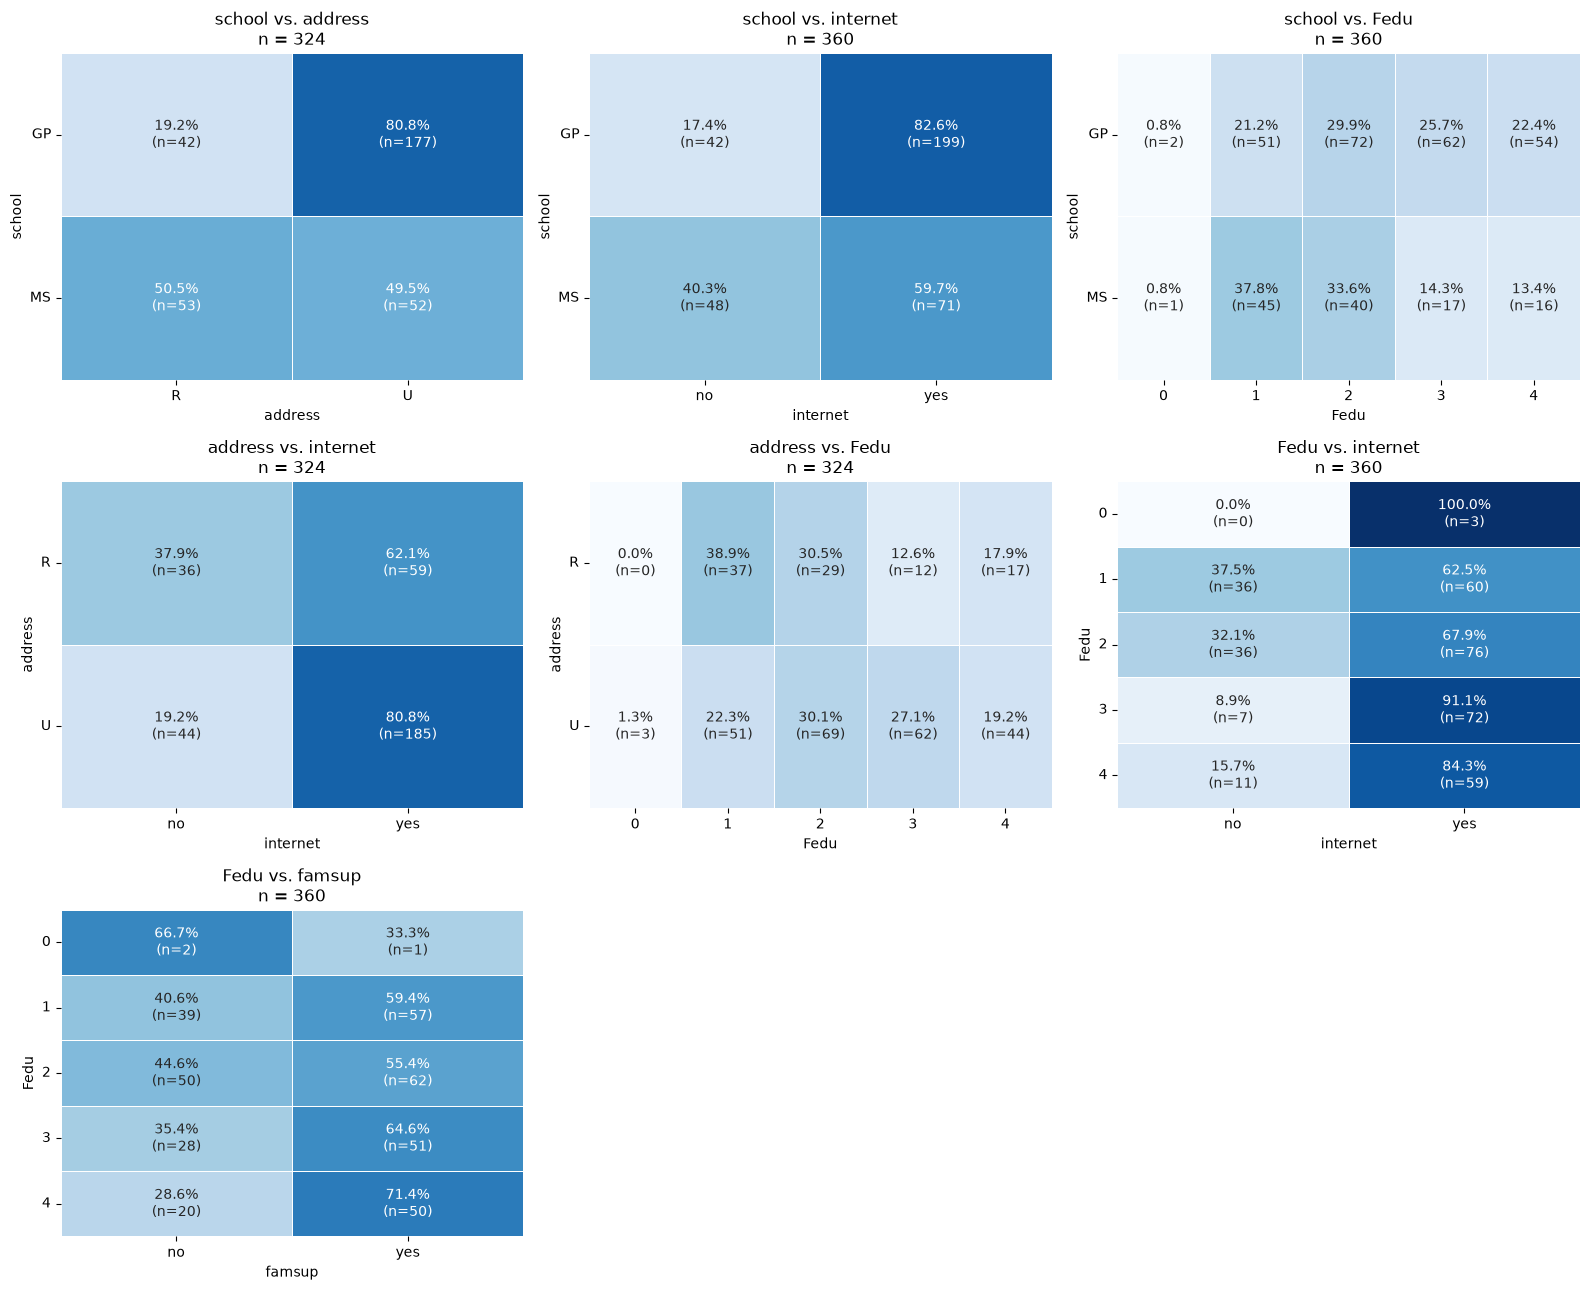

In [31]:
fig, axes = plt.subplots(3, 3, figsize=(16, 13))

for (var1, var2), ax in zip(
    parejas_categoricas, axes.flatten()
):

    datos = df[[var1, var2]].dropna()

    frecuencia = pd.crosstab(
        datos[var1], datos[var2]
    )

    porcentaje = pd.crosstab(
        datos[var1],
        datos[var2],
        normalize="index"
    ) * 100

    # Mostrar porcentaje y frecuencia absoluta
    etiquetas = (
        porcentaje.round(1).astype(str) + "%\n(n=" +
        frecuencia.astype(str) + ")"
    )

    sns.heatmap(
        porcentaje,
        annot=etiquetas,
        fmt="",
        cmap="Blues",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        cbar=False,
        ax=ax
    )

    ax.set_title(
        f"{var1} vs. {var2}\n"
        f"n = {len(datos)}"
    )

    ax.set_yticklabels(
        ax.get_yticklabels(),
        rotation=0
    )

# Eliminar espacios sin gráficas
for ax in axes.flatten()[len(parejas_categoricas):]:
    ax.remove()

plt.tight_layout()
plt.show()

Los mapas de calor permiten identificar que las características de los estudiantes no se distribuyen de manera homogénea entre los grupos analizados. Particularmente, GP presenta una mayor proporción de estudiantes que viven en zonas urbanas, tienen acceso a internet y cuyos padres poseen niveles educativos superiores. Asimismo, se observa que los estudiantes urbanos tienen una mayor proporción de acceso a internet respecto a los estudiantes rurales.

Respecto al nivel educativo del padre, los niveles 3 y 4 presentan mayores proporciones de acceso a internet y apoyo educativo familiar que los niveles 1 y 2, aunque estos comportamientos no siguen tendencias estrictamente crecientes.

La inclusión de las frecuencias absolutas dentro de los mapas de calor resulta importante para evitar interpretaciones incorrectas, por lo que este porcentaje debe interpretarse con precaución.


### Análisis longitudinal del rendimiento académico

El conjunto de datos contiene tres mediciones del rendimiento académico correspondientes a diferentes periodos de evaluación de un mismo estudiante. Debido a esta estructura, las observaciones de G1, G2 y G3 no pueden considerarse independientes entre sí.

Aunque el análisis univariado mostró un incremento progresivo de las calificaciones medias, la presencia de valores faltantes en G1 y G2 implica que estas medias se calcularon sobre conjuntos de estudiantes potencialmente diferentes.

Por esta razón, se realizará un análisis longitudinal basado en observaciones apareadas, con el objetivo de estudiar los cambios individuales en el rendimiento académico y distinguir entre incrementos generales de las medias y mejoras efectivamente observadas en los mismos estudiantes.

Utilizaremos las dos primeras estrategias. La comparación de estudiantes con las tres calificaciones disponibles será nuestro análisis principal, mientras que el análisis por parejas servirá como complemento para evaluar la sensibilidad de los resultados.

### Observaciones apareadas

In [38]:
periodos = ["G1", "G2", "G3"]
datos_longitudinales = df[periodos].dropna().copy()

parejas_periodos = [
    ("G1", "G2"),
    ("G2", "G3"),
    ("G1", "G3")
]

disponibilidad = []

for inicial, final in parejas_periodos:

    datos_pareja = df[[inicial, final]].dropna()

    disponibilidad.append({
        "Comparacion": f"{inicial} -> {final}",
        "n": len(datos_pareja),
        "porcentaje_muestra": len(datos_pareja) / len(df) * 100
    })

disponibilidad.append({
    "Comparacion": "G1, G2, G3",
    "n": len(datos_longitudinales),
    "porcentaje_muestra": len(datos_longitudinales) / len(df) * 100
})

display(pd.DataFrame(disponibilidad).round(3))

,Comparacion,n,porcentaje_muestra
0,G1 -> G2,299,83.056
1,G2 -> G3,324,90.000
2,G1 -> G3,331,91.944
3,"G1, G2, G3",299,83.056


### Comparación de medias marginales y apareadas

In [39]:
comparacion_periodos = pd.DataFrame({
    "n_marginal": df[periodos].count(),
    "media_marginal": df[periodos].mean(),
    "mediana_marginal": df[periodos].median(),
    "DE_marginal": df[periodos].std(),

    "n_apareado": datos_longitudinales.count(),
    "media_apareada": datos_longitudinales.mean(),
    "mediana_apareada": datos_longitudinales.median(),
    "DE_apareada": datos_longitudinales.std()
})

comparacion_periodos["diferencia_medias"] = (
    comparacion_periodos["media_apareada"] -
    comparacion_periodos["media_marginal"]
)

display(comparacion_periodos.round(3))

,n_marginal,media_marginal,mediana_marginal,DE_marginal,n_apareado,media_apareada,mediana_apareada,DE_apareada,diferencia_medias
G1,331,11.574,12.0,2.780,299,11.602,12.0,2.791,0.028
G2,324,11.719,11.0,2.832,299,11.729,12.0,2.867,0.010
G3,360,12.050,12.0,3.049,299,11.967,12.0,3.145,-0.083


El análisis de disponibilidad permitió identificar 299 estudiantes con calificaciones registradas en los tres periodos académicos, equivalentes al 83.06 % de la muestra original. Se seleccionó este subconjunto como base del análisis longitudinal, evitando excluir estudiantes por valores faltantes en variables que no intervienen directamente en esta comparación.

Al comparar las estadísticas marginales con las obtenidas sobre las observaciones apareadas, se encontraron diferencias reducidas en las medidas de tendencia central y dispersión. La tendencia creciente de las calificaciones medias se mantuvo al utilizar una muestra común, aunque el incremento acumulado entre G1 y G3 disminuyó de aproximadamente 0.476 a 0.365 puntos.

Asimismo, se observó un incremento progresivo de la desviación estándar, lo que indica una mayor heterogeneidad en las calificaciones conforme avanzan los periodos académicos.
Estos resultados permiten identificar una mejoría promedio dentro del subconjunto analizado, pero no determinar qué proporción de estudiantes mejoró individualmente ni establecer significancia estadística. Por esta razón, el siguiente análisis se centrará en las diferencias intraindividuales entre periodos.

## Análisis de los cambios individuales

In [40]:
datos_longitudinales["delta_12"] = (
    datos_longitudinales["G2"] -
    datos_longitudinales["G1"]
)

datos_longitudinales["delta_23"] = (
    datos_longitudinales["G3"] -
    datos_longitudinales["G2"]
)

datos_longitudinales["delta_13"] = (
    datos_longitudinales["G3"] -
    datos_longitudinales["G1"]
)

variables_cambio = [
    "delta_12",
    "delta_23",
    "delta_13"
]

display(datos_longitudinales.head())

,G1,G2,G3,delta_12,delta_23,delta_13
0,14.0,13.0,13,-1.0,0.0,-1.0
1,18.0,19.0,19,1.0,0.0,1.0
2,10.0,10.0,10,0.0,0.0,0.0
3,11.0,11.0,12,0.0,1.0,1.0
4,13.0,12.0,13,-1.0,1.0,0.0


El primer resultado interesante es que las medias son positivas, pero las medianas son iguales a cero en las tres comparaciones. Aunque existe un incremento promedio de las calificaciones, el cambio central de las distribuciones corresponde a mantener la misma nota. Además La transición G2 - G3 presenta la menor desviación estándar de los cambios individuales, con 1.138 puntos, mientras que el cambio acumulado G1 - G3 presenta la mayor, con 1.642 puntos

### Estadística descriptiva de los cambios

In [41]:
cambios = datos_longitudinales[variables_cambio]
resumen_cambios = cambios.describe().T

resumen_cambios["IQR"] = (
    resumen_cambios["75%"] -
    resumen_cambios["25%"]
)

resumen_cambios["asimetria"] = cambios.skew()
resumen_cambios["exceso_curtosis"] = cambios.kurt()

display(resumen_cambios.round(3))

,count,mean,std,min,25%,50%,75%,max,IQR,asimetria,exceso_curtosis
delta_12,299.0,0.127,1.411,-9.0,-1.0,0.0,1.0,5.0,2.0,-1.072,7.337
delta_23,299.0,0.237,1.138,-8.0,0.0,0.0,1.0,3.0,1.0,-2.840,16.761
delta_13,299.0,0.365,1.642,-9.0,0.0,0.0,1.0,5.0,1.0,-2.032,9.981


### Proporción de estudiantes que mejoran, empeoran o mantienen su calificación

In [42]:
resultados_cambios = []

for variable in variables_cambio:
    delta = datos_longitudinales[variable]
    n = delta.count()
    mejoran = (delta > 0).sum()
    mantienen = (delta == 0).sum()
    empeoran = (delta < 0).sum()

    resultados_cambios.append({
        "comparacion": variable,
        "n": n,
        "mejoran": mejoran,
        "mantienen": mantienen,
        "empeoran": empeoran,
        "mejoran_%": mejoran / n * 100,
        "mantienen_%": mantienen / n * 100,
        "empeoran_%": empeoran / n * 100
    })

tabla_cambios = pd.DataFrame(resultados_cambios)

display(tabla_cambios.round(3))

,comparacion,n,mejoran,mantienen,empeoran,mejoran_%,mantienen_%,empeoran_%
0,delta_12,299,125,81,93,41.806,27.090,31.104
1,delta_23,299,123,135,41,41.137,45.151,13.712
2,delta_13,299,145,88,66,48.495,29.431,22.074


Entre G1 y G2, el 41.81 % de los estudiantes mejoró su calificación, mientras que el 31.10 % presentó una disminución. En la transición entre G2 y G3, la proporción de estudiantes que empeoraron disminuyó al 13.71 %, y el porcentaje de estudiantes que mantuvieron su calificación aumentó al 45.15 %.

Respecto al cambio acumulado entre G1 y G3, se obtuvo un incremento promedio de 0.365 puntos. El 48.49 % de los estudiantes mejoró su calificación, el 29.43 % la mantuvo y el 22.07 % presentó una disminución. Aunque mejorar fue el resultado más frecuente, no representó a la mayoría absoluta de los estudiantes.

Por otro lado, las distribuciones de las diferencias presentaron asimetría negativa y excesos de curtosis elevados, particularmente en la transición entre G2 y G3. Estos resultados sugieren la presencia de disminuciones individuales pronunciadas en comparación con la concentración central de los cambios.

Se decidió conservar todas las diferencias observadas, ya que provienen de calificaciones válidas

## Visualización de la distribución de los cambios

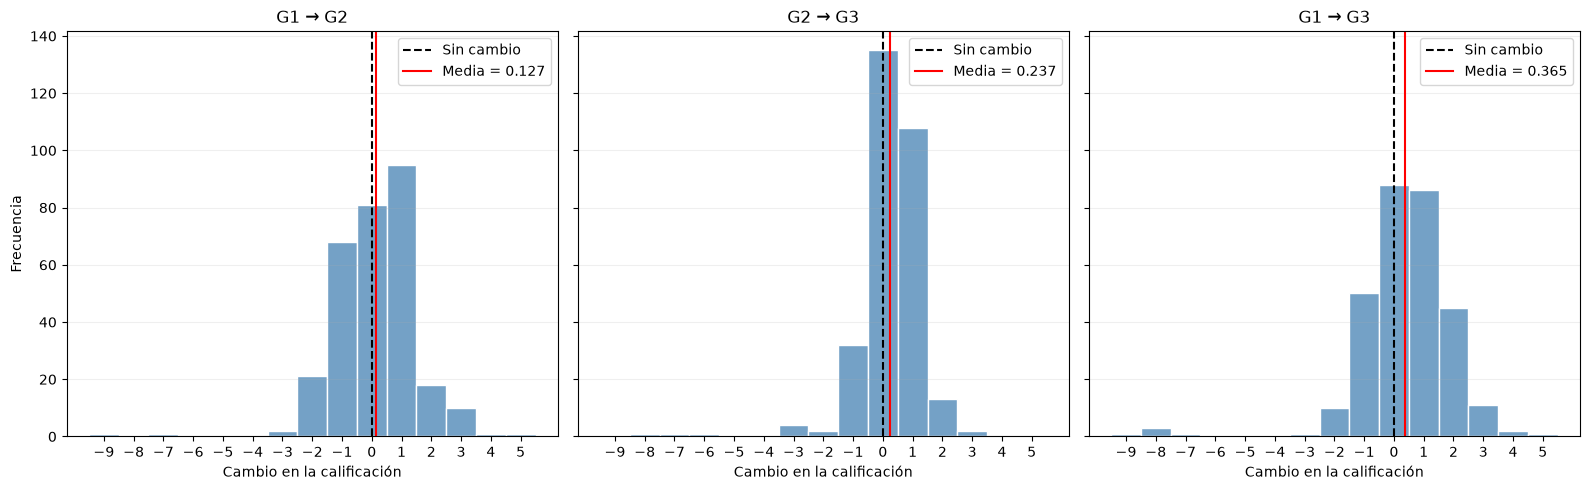

In [ ]:
import numpy as np

nombres_cambios = {
    "delta_12": "G1 - G2",
    "delta_23": "G2 - G3",
    "delta_13": "G1 - G3"
}

limite_min = int(cambios.min().min())
limite_max = int(cambios.max().max())

bins = np.arange(
    limite_min - 0.5,
    limite_max + 1.5,
    1
)

fig, axes = plt.subplots(
    1, 3, figsize=(16, 5),
    sharex=True,
    sharey=True
)

for variable, ax in zip(variables_cambio, axes):

    delta = datos_longitudinales[variable]

    sns.histplot(
        delta,
        bins=bins,
        ax=ax,
        color="steelblue",
        edgecolor="white"
    )

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        label="Sin cambio"
    )

    ax.axvline(
        delta.mean(),
        color="red",
        linestyle="-",
        label=f"Media = {delta.mean():.3f}"
    )

    ax.set_title(nombres_cambios[variable])
    ax.set_xlabel("Cambio en la calificación")
    ax.set_ylabel("Frecuencia")
    ax.set_xticks(range(limite_min, limite_max + 1))
    ax.legend()
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

En las tres comparaciones se observa una concentración de los cambios alrededor de cero, especialmente entre −1 y +1 puntos.

En la transición G1 - G2, el cambio más frecuente es un incremento de un punto. Por otro lado, en G2 - G3 y G1 - G3, el cambio más frecuente es cero.
También se observa que las distribuciones presentan colas negativas más pronunciadas que las positivas. Aunque las medias son positivas, existen estudiantes que experimentaron disminuciones considerablemente mayores que los incrementos observados en otros estudiantes.

### Comparación mediante boxplots

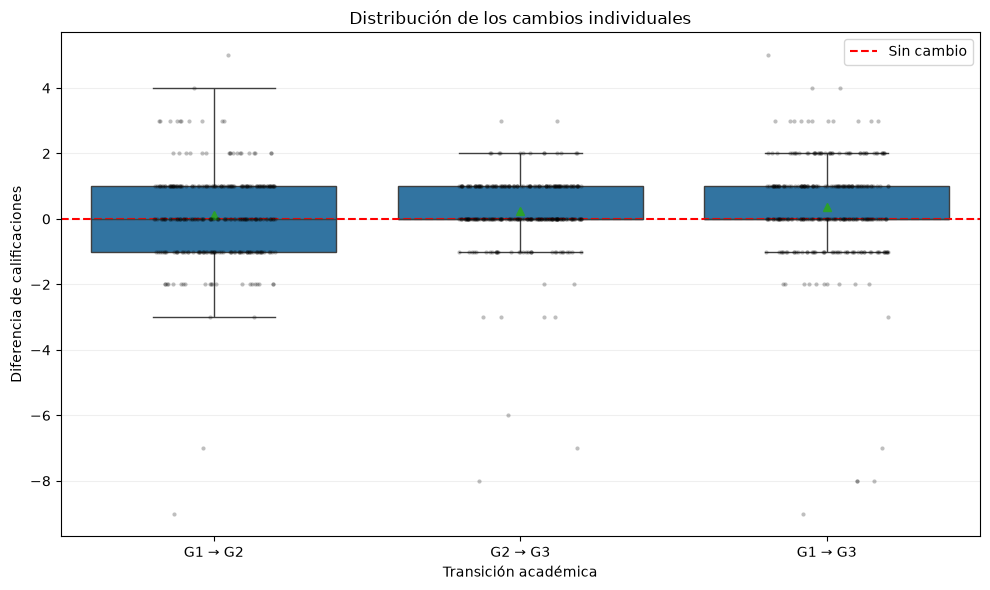

In [46]:
cambios_largos = datos_longitudinales[
    variables_cambio
].melt(
    var_name="comparacion",
    value_name="cambio"
)

cambios_largos["comparacion"] = (
    cambios_largos["comparacion"].map(nombres_cambios)
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=cambios_largos,
    x="comparacion",
    y="cambio",
    showmeans=True,
    showfliers=False
)

sns.stripplot(
    data=cambios_largos,
    x="comparacion",
    y="cambio",
    color="black",
    alpha=0.25,
    jitter=0.2,
    size=3
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
    label="Sin cambio"
)

plt.title("Distribución de los cambios individuales")
plt.xlabel("Transición académica")
plt.ylabel("Diferencia de calificaciones")
plt.grid(axis="y", alpha=0.2)
plt.legend()

plt.tight_layout()
plt.show()

Las medianas de las tres distribuciones coinciden con la línea de referencia de cero. l 50 % central de las observaciones se encuentra entre cero y un punto de cambio. En contraste, para G1 - G2, este intervalo se encuentra entre −1 y +1 puntos.

Esto permite identificar que los cambios acumulados pueden presentar una mayor dispersión general, medida mediante la desviación estándar, sin necesariamente presentar una mayor dispersión en el 50 % central.


### Proporciones de evolución académica

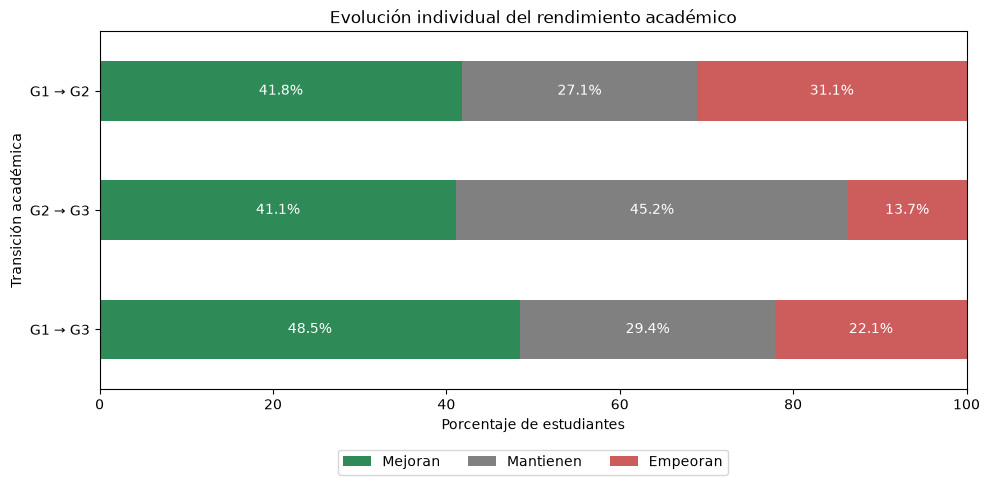

In [44]:
proporciones = tabla_cambios.set_index(
    "comparacion"
)[[
    "mejoran_%",
    "mantienen_%",
    "empeoran_%"
]].copy()

proporciones.index = proporciones.index.map(
    nombres_cambios
)

proporciones.columns = [
    "Mejoran",
    "Mantienen",
    "Empeoran"
]

ax = proporciones.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 5),
    color=["seagreen", "gray", "indianred"]
)

for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.1f%%",
        label_type="center",
        color="white"
    )

ax.set_xlim(0, 100)
ax.set_xlabel("Porcentaje de estudiantes")
ax.set_ylabel("Transición académica")
ax.set_title("Evolución individual del rendimiento académico")
ax.invert_yaxis()

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3
)

plt.tight_layout()
plt.show()

La comparación de proporciones muestra que entre G2 y G3 existe una mayor estabilidad de las calificaciones respecto a la primera transición. En el cambio acumulado entre G1 y G3, aproximadamente el 77.93 % de los estudiantes mantuvo o mejoró su calificación, aunque únicamente el 48.49 % presentó una mejoría.

En conjunto, los resultados muestran que el incremento promedio del rendimiento académico no implica una evolución homogénea entre los estudiantes. La asimetría, la concentración de diferencias iguales a cero y la presencia de cambios extremos deberán considerarse durante la selección de los métodos inferenciales.

## Análisis de sensibilidad ante valores faltantes

Con el objetivo de evaluar la sensibilidad de los resultados frente a la selección de observaciones, se compararon los estadísticos obtenidos mediante trayectorias completas con aquellos calculados utilizando todos los estudiantes disponibles para cada pareja de periodos.

In [48]:
resultados_sensibilidad = []

for inicial, final in parejas_periodos:

    estrategias = {
        "Trayectorias completas": datos_longitudinales[
            [inicial, final]
        ],
        "Casos disponibles": df[
            [inicial, final]
        ].dropna()
    }

    for estrategia, datos in estrategias.items():

        delta = datos[final] - datos[inicial]

        resultados_sensibilidad.append({
            "comparacion": f"{inicial} - {final}",
            "estrategia": estrategia,
            "n": len(delta),
            "media": delta.mean(),
            "mediana": delta.median(),
            "DE": delta.std(),
            "IQR": delta.quantile(0.75) -
                   delta.quantile(0.25),
            "mejoran_%": (delta > 0).mean() * 100,
            "mantienen_%": (delta == 0).mean() * 100,
            "empeoran_%": (delta < 0).mean() * 100
        })

tabla_sensibilidad = pd.DataFrame(
    resultados_sensibilidad
)

display(tabla_sensibilidad.round(3))

,comparacion,estrategia,n,media,mediana,DE,IQR,mejoran_%,mantienen_%,empeoran_%
0,G1 - G2,Trayectorias completas,299,0.127,0.0,1.411,2.0,41.806,27.090,31.104
1,G1 - G2,Casos disponibles,299,0.127,0.0,1.411,2.0,41.806,27.090,31.104
2,G2 - G3,Trayectorias completas,299,0.237,0.0,1.138,1.0,41.137,45.151,13.712
3,G2 - G3,Casos disponibles,324,0.269,0.0,1.126,1.0,42.284,44.444,13.272
4,G1 - G3,Trayectorias completas,299,0.365,0.0,1.642,1.0,48.495,29.431,22.074
5,G1 - G3,Casos disponibles,331,0.447,1.0,1.649,1.0,50.755,28.399,20.846


### Cuantificación de las diferencias entre estrategias

In [49]:
metricas = [
    "n",
    "media",
    "mediana",
    "DE",
    "IQR",
    "mejoran_%",
    "mantienen_%",
    "empeoran_%"
]

completos = tabla_sensibilidad[
    tabla_sensibilidad["estrategia"] ==
    "Trayectorias completas"
].set_index("comparacion")[metricas]

disponibles = tabla_sensibilidad[
    tabla_sensibilidad["estrategia"] ==
    "Casos disponibles"
].set_index("comparacion")[metricas]

diferencias_sensibilidad = disponibles - completos

display(diferencias_sensibilidad.round(3))

,n,media,mediana,DE,IQR,mejoran_%,mantienen_%,empeoran_%
comparacion,,,,,,,,
G1 - G2,0,0.000,0.0,0.000,0.0,0.000,0.000,0.000
G2 - G3,25,0.031,0.0,-0.012,0.0,1.147,-0.706,-0.441
G1 - G3,32,0.083,1.0,0.008,0.0,2.260,-1.033,-1.228


La comparación entre G1 y G3 presentó una mayor sensibilidad. Al incorporar 32 estudiantes adicionales, el cambio promedio aumentó aproximadamente 0.083 puntos y la mediana pasó de cero a un punto. Asimismo, la proporción de estudiantes que mejoraron aumentó 2.260 puntos porcentuales, superando ligeramente el 50 %.

En términos generales, la dirección positiva y la reducida magnitud de los cambios promedio se mantienen bajo ambas estrategias. Sin embargo, la conclusión sobre si la mayoría de los estudiantes mejoró su calificación depende del subconjunto utilizado.
Estos resultados no permiten determinar el mecanismo que originó los valores faltantes, pero muestran la importancia de documentar la selección de observaciones y evaluar su impacto sobre las conclusiones.


Este análisis longitudinal permitió identificar un incremento promedio de las calificaciones a través de los tres periodos académicos, incluso al comparar las observaciones de los mismos estudiantes.

Sin embargo, las diferencias individuales mostraron que esta evolución no fue homogénea. Los cambios se concentraron principalmente alrededor de cero, coexistiendo estudiantes que mejoraron, mantuvieron o disminuyeron sus calificaciones. Además, las distribuciones presentaron asimetría negativa y disminuciones individuales pronunciadas.

El análisis de sensibilidad permitió comprobar que la tendencia promedio positiva se mantiene al modificar la estrategia de selección de observaciones, aunque algunos estadísticos y proporciones presentan diferencias.


## Análisis multivariado

Se utilizarán matrices de covarianzas y correlaciones de Pearson y Spearman, documentando el número de observaciones disponibles para cada pareja de variables.


Observaciones disponibles


,G1,G2,G3,age,absences
G1,331,299,331,331,293
G2,299,324,324,324,286
G3,331,324,360,360,317
age,331,324,360,360,317
absences,293,286,317,317,317



Covarianzas


,G1,G2,G3,age,absences
G1,7.730,7.009,7.315,-0.423,-2.591
G2,7.009,8.023,8.145,-0.143,-2.123
G3,7.315,8.145,9.296,-0.161,-2.032
age,-0.423,-0.143,-0.161,1.519,0.566
absences,-2.591,-2.123,-2.032,0.566,24.471



Pearson


,G1,G2,G3,age,absences
G1,1.000,0.876,0.848,-0.125,-0.189
G2,0.876,1.000,0.931,-0.041,-0.152
G3,0.848,0.931,1.000,-0.043,-0.134
age,-0.125,-0.041,-0.043,1.000,0.098
absences,-0.189,-0.152,-0.134,0.098,1.000



Spearman


,G1,G2,G3,age,absences,Fedu
G1,1.000,0.897,0.891,-0.109,-0.193,0.261
G2,0.897,1.000,0.945,-0.048,-0.184,0.291
G3,0.891,0.945,1.000,-0.015,-0.192,0.267
age,-0.109,-0.048,-0.015,1.000,0.080,-0.107
absences,-0.193,-0.184,-0.192,0.080,1.000,-0.002
Fedu,0.261,0.291,0.267,-0.107,-0.002,1.000


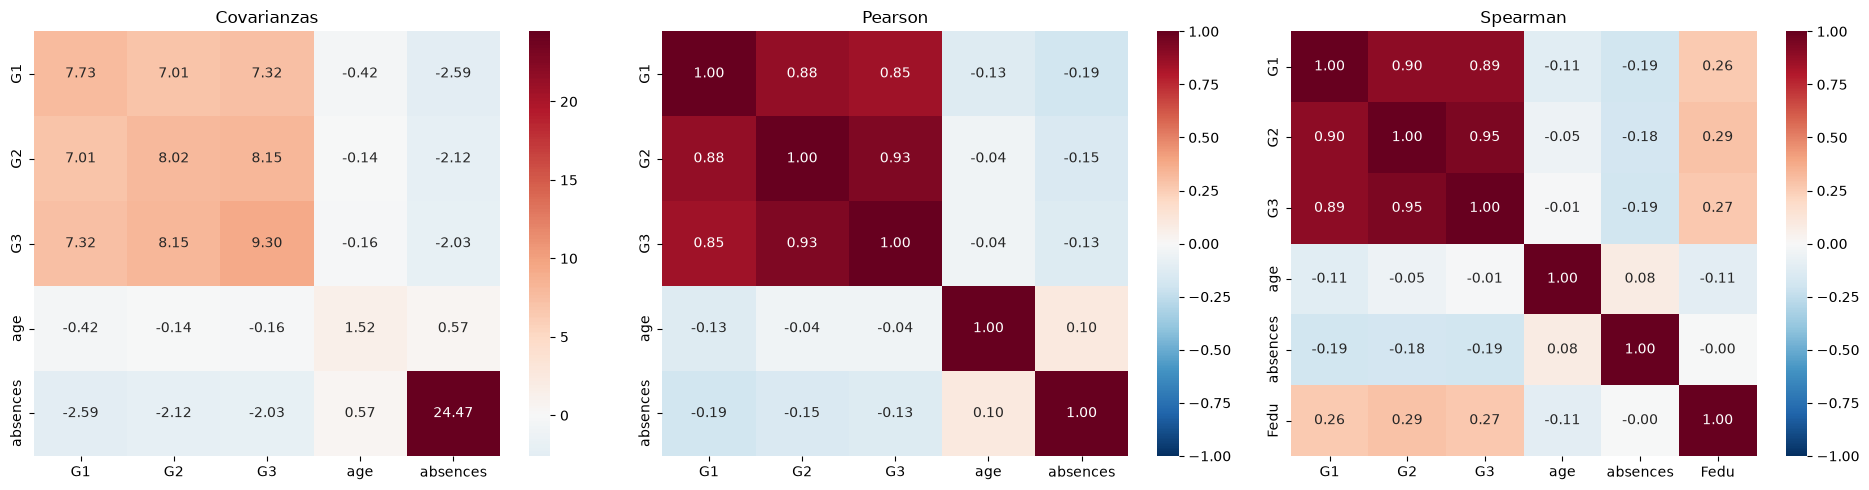

In [50]:
variables_multivariadas = [
    "G1", "G2", "G3", "age", "absences"
]

datos_multi = df[variables_multivariadas].copy()

# Matriz de observaciones disponibles
observados = datos_multi.notna().astype(int)
matriz_n = observados.T @ observados

# Covarianzas
matriz_cov = datos_multi.cov()

# Pearson
matriz_pearson = datos_multi.corr(method="pearson")

# Spearman, incluyendo Fedu por ser ordinal
datos_spearman = df[variables_multivariadas + ["Fedu"]].copy()
datos_spearman["Fedu"] = datos_spearman["Fedu"].astype(int)

matriz_spearman = datos_spearman.corr(method="spearman")

for nombre, matriz in {
    "Observaciones disponibles": matriz_n,
    "Covarianzas": matriz_cov,
    "Pearson": matriz_pearson,
    "Spearman": matriz_spearman
}.items():

    print(f"\n{nombre}")
    display(matriz.round(3))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.heatmap(
    matriz_cov, annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, ax=axes[0]
)

sns.heatmap(
    matriz_pearson, annot=True, fmt=".2f",
    cmap="RdBu_r", vmin=-1, vmax=1,
    center=0, ax=axes[1]
)

sns.heatmap(
    matriz_spearman, annot=True, fmt=".2f",
    cmap="RdBu_r", vmin=-1, vmax=1,
    center=0, ax=axes[2]
)

axes[0].set_title("Covarianzas")
axes[1].set_title("Pearson")
axes[2].set_title("Spearman")

plt.tight_layout()
plt.show()

## Correlaciones sobre una muestra común

In [51]:
datos_multi_completos = datos_multi.dropna()

pearson_completos = datos_multi_completos.corr()

diferencia_correlaciones = (
    pearson_completos - matriz_pearson
)

print("Casos completos:", len(datos_multi_completos))

print("\nPearson con muestra común")
display(pearson_completos.round(3))

print("\nDiferencias respecto a casos disponibles por pareja")
display(diferencia_correlaciones.round(3))

Casos completos: 266

Pearson con muestra común


,G1,G2,G3,age,absences
G1,1.000,0.874,0.850,-0.073,-0.189
G2,0.874,1.000,0.931,0.021,-0.154
G3,0.850,0.931,1.000,-0.004,-0.116
age,-0.073,0.021,-0.004,1.000,0.089
absences,-0.189,-0.154,-0.116,0.089,1.000



Diferencias respecto a casos disponibles por pareja


,G1,G2,G3,age,absences
G1,0.000,-0.002,0.001,0.052,0.000
G2,-0.002,0.000,0.000,0.062,-0.003
G3,0.001,0.000,0.000,0.039,0.019
age,0.052,0.062,0.039,0.000,-0.009
absences,0.000,-0.003,0.019,-0.009,0.000
